Аналіз структури датасету


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   object 
 1   label                2000 non-null   object 
 2   source_model         2000 non-null   object 
 3   domain               2000 non-null   object 
 4   text_content         2000 non-null   object 
 5   topic_hint           2000 non-null   object 
 6   word_count           2000 non-null   int64  
 7   avg_sentence_length  2000 non-null   float64
 8   generation_method    2000 non-null   object 
dtypes: float64(1), int64(1), object(7)
memory usage: 140.8+ KB

Баланс класів
label
human    1334
ai        666
Name: count, dtype: int64

Артефакти
Порожніх значень у текстах: 0
Дублікатів: 0


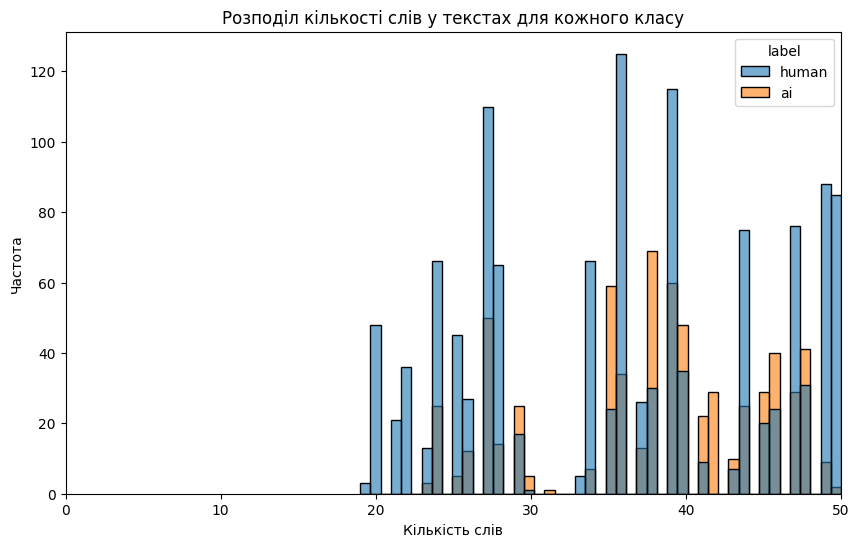

Кількість записів після фінального очищення: 2000


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#1 Завантаження датасету
file_path = 'sample_data/ai_vs_human_text_2026.csv'
df = pd.read_csv(file_path)

# ЯВНО ВКАЗУЄМО НАЗВИ КОЛОНОК ЗГІДНО З ВАШИМ ДАТАСЕТОМ
text_col = 'text_content'
label_col = 'label'

print("Аналіз структури датасету")
display(df.head())
df.info()

#2 Перевірка балансу класів
print("\nБаланс класів")
print(df[label_col].value_counts())

#3 Виявлення артефактів (дублікати, порожні рядки)
print("\nАртефакти")
print(f"Порожніх значень у текстах: {df[text_col].isnull().sum()}")
print(f"Дублікатів: {df.duplicated().sum()}")

# Очищення від порожніх рядків та дублікатів
df = df.dropna(subset=[text_col]).drop_duplicates()

#4 Побудова гістограм розподілу кількості слів
#Рахуємо слова саме в колонці text_content
df['word_count'] = df[text_col].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 6))
#Будуємо графік без kde, щоб уникнути математичних помилок
sns.histplot(data=df, x='word_count', hue=label_col, bins=50, kde=False, alpha=0.6)
plt.title('Розподіл кількості слів у текстах для кожного класу')
plt.xlabel('Кількість слів')
plt.ylabel('Частота')

#Обмеження відображення 95-м перцентилем
max_val = df['word_count'].quantile(0.95)
if max_val > 0:
    plt.xlim(0, max_val)

plt.show()

#Видалення надмірно коротких текстів
df = df[df['word_count'] >= 5].copy()
print(f"Кількість записів після фінального очищення: {len(df)}")

In [5]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 78.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [8]:
import spacy

#Завантаження мовної моделі
nlp = spacy.load("en_core_web_sm")

print("Виконується попередня обробка текстів (це може зайняти певний час)...")

#Використання nlp.pipe з batching
processed_docs = []

#Обробляємо тексти з правильної колонки text_content
for doc in nlp.pipe(df[text_col].astype(str), batch_size=256):
    #Лематизація, видалення стоп-слів та небуквених символів, зведення до нижнього регістру
    tokens = [token.lemma_.lower() for token in doc if token.is_alpha and not token.is_stop]
    processed_docs.append(tokens)

#Додавання результатів як нової колонки
df['processed_tokens'] = processed_docs

print("\nРезультат попередньої обробки")
display(df[[text_col, 'processed_tokens']].head())

Виконується попередня обробка текстів (це може зайняти певний час)...

Результат попередньої обробки


,text_content,processed_tokens
0,can we talk about gene editing ethics for a se...,"[talk, gene, edit, ethic, sec, feel, like, peo..."
1,update on election integrity concerns: it's co...,"[update, election, integrity, concern, complic..."
2,Analysts are closely watching developments rel...,"[analyst, closely, watch, development, relate,..."
3,This paper examines genomic research breakthro...,"[paper, examine, genomic, research, breakthrou..."
4,Existing literature on student debt crisis has...,"[exist, literature, student, debt, crisis, pre..."


In [11]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 23.6 MB/s eta 0:00:00


In [12]:
from gensim.models import FastText

print("Підготовка корпусу для FastText...")
# FastText очікує на вхід список списків слів (наші processed_tokens)
corpus = df['processed_tokens'].tolist()

print("Навчання моделі FastText (це займе трохи часу)...")
# Параметри згідно з методичкою
model_ft = FastText(
    sentences=corpus,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,          # Skip-gram
    workers=4,
    seed=42
)

print(f"Модель успішно навчена! Розмір словника: {len(model_ft.wv)}")
# Перевіримо, як виглядає вектор для одного слова
sample_word = corpus[0][0] if corpus and corpus[0] else "test"
if sample_word in model_ft.wv:
    print(f"Розмірність вектора для слова '{sample_word}': {model_ft.wv[sample_word].shape}")

Підготовка корпусу для FastText...
Навчання моделі FastText (це займе трохи часу)...
Модель успішно навчена! Розмір словника: 510
Розмірність вектора для слова 'talk': (100,)


In [13]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

print("Розрахунок TF-IDF ваг...")
# Для TF-IDF нам потрібні тексти у вигляді рядків (з'єднуємо токени назад)
df['processed_text_str'] = df['processed_tokens'].apply(lambda tokens: ' '.join(tokens))

# Навчаємо TF-IDF векторизатор
tfidf = TfidfVectorizer()
tfidf.fit(df['processed_text_str'])

# Створюємо словник: слово -> його IDF значення (глобальна вага слова)
# Використовуємо idf_ атрибут згідно з формулою (4) методички
word2tfidf = dict(zip(tfidf.get_feature_names_out(), tfidf.idf_))

# --- Функції агрегації з методички ---
def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])

    if not vectors:
        return np.zeros(model.vector_size)

    weights = np.array(weights)
    # Нормалізація ваг, щоб їх сума дорівнювала 1 (запобігає діленню на нуль, якщо всі ваги 0)
    if weights.sum() > 0:
        weights = weights / weights.sum()
    else:
        weights = np.ones(len(weights)) / len(weights)

    return np.average(vectors, axis=0, weights=weights)

print("Векторизація документів (Mean Pooling)...")
# Застосовуємо Mean Pooling
df['vector_mean'] = df['processed_tokens'].apply(lambda x: mean_pooling(x, model_ft))

print("Векторизація документів (TF-IDF Weighted)...")
# Застосовуємо TF-IDF Weighted Mean
df['vector_tfidf'] = df['processed_tokens'].apply(lambda x: tfidf_weighted_pooling(x, model_ft, word2tfidf))

print("\n=== Векторизація завершена ===")
print(f"Розмірність вектора Mean Pooling: {df['vector_mean'].iloc[0].shape}")
print(f"Розмірність вектора TF-IDF Weighted: {df['vector_tfidf'].iloc[0].shape}")

Розрахунок TF-IDF ваг...
Векторизація документів (Mean Pooling)...
Векторизація документів (TF-IDF Weighted)...

=== Векторизація завершена ===
Розмірність вектора Mean Pooling: (100,)
Розмірність вектора TF-IDF Weighted: (100,)


In [15]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder

print("Етап 5: Навчання та оцінка класифікаторів")

# Перетворення текстових міток (Human, AI) у числові (0, 1)
le = LabelEncoder()
y = le.fit_transform(df[label_col])

# Підготовка матриць ознак (X) для обох методів
X_mean = np.vstack(df['vector_mean'].values)
X_tfidf = np.vstack(df['vector_tfidf'].values)

# Створення словника для зберігання результатів
results = []

# Визначаємо класифікатори згідно з методичкою
classifiers = {
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'LogReg': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

# Функція для навчання та оцінки
def train_and_evaluate(X, y, method_name):
    # Розбиття на train/test згідно з методичкою (80/20, stratify=y)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    for clf_name, clf in classifiers.items():
        print(f"Навчання {clf_name} на векторах {method_name}...")
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        # Для ROC-AUC нам потрібні ймовірності (probability) позитивного класу
        if hasattr(clf, "predict_proba"):
            y_prob = clf.predict_proba(X_test)[:, 1]
        else:
            y_prob = clf.decision_function(X_test)

        # Розрахунок метрик згідно з методичкою
        res = {
            'Метод агрегації': method_name,
            'Класифікатор': clf_name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
            'F1-score (macro)': f1_score(y_test, y_pred, average='macro'),
            'ROC-AUC': roc_auc_score(y_test, y_prob)
        }
        results.append(res)

# Запускаємо оцінку для обох методів векторизації
train_and_evaluate(X_mean, y, 'Mean Pooling')
train_and_evaluate(X_tfidf, y, 'TF-IDF Weighted')

# Виведення результатів у вигляді гарної таблиці
results_df = pd.DataFrame(results)
print("\nРезультати оцінки класифікаторів")
display(results_df.round(4))

Етап 5: Навчання та оцінка класифікаторів
Навчання SVM на векторах Mean Pooling...
Навчання LogReg на векторах Mean Pooling...
Навчання KNN на векторах Mean Pooling...
Навчання SVM на векторах TF-IDF Weighted...
Навчання LogReg на векторах TF-IDF Weighted...
Навчання KNN на векторах TF-IDF Weighted...

Результати оцінки класифікаторів


,Метод агрегації,Класифікатор,Accuracy,Balanced Accuracy,F1-score (macro),ROC-AUC
0,Mean Pooling,SVM,1.0000,1.0000,1.0000,1.0
1,Mean Pooling,LogReg,0.9975,0.9962,0.9972,1.0
2,Mean Pooling,KNN,1.0000,1.0000,1.0000,1.0
3,TF-IDF Weighted,SVM,1.0000,1.0000,1.0000,1.0
4,TF-IDF Weighted,LogReg,0.9975,0.9962,0.9972,1.0
5,TF-IDF Weighted,KNN,1.0000,1.0000,1.0000,1.0


1. t-SNE Візуалізація векторних просторів
Обчислення t-SNE (це може зайняти хвилину)...


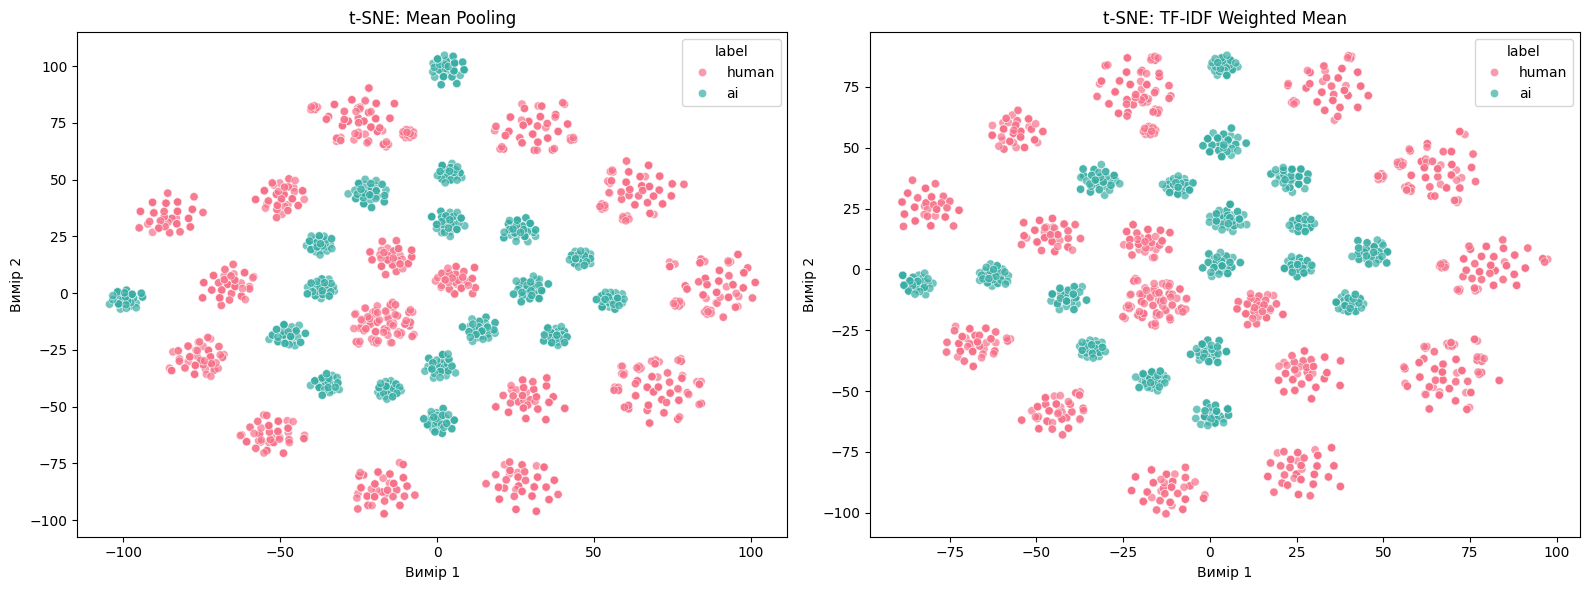


2. Матриці плутанини (Confusion Matrices)


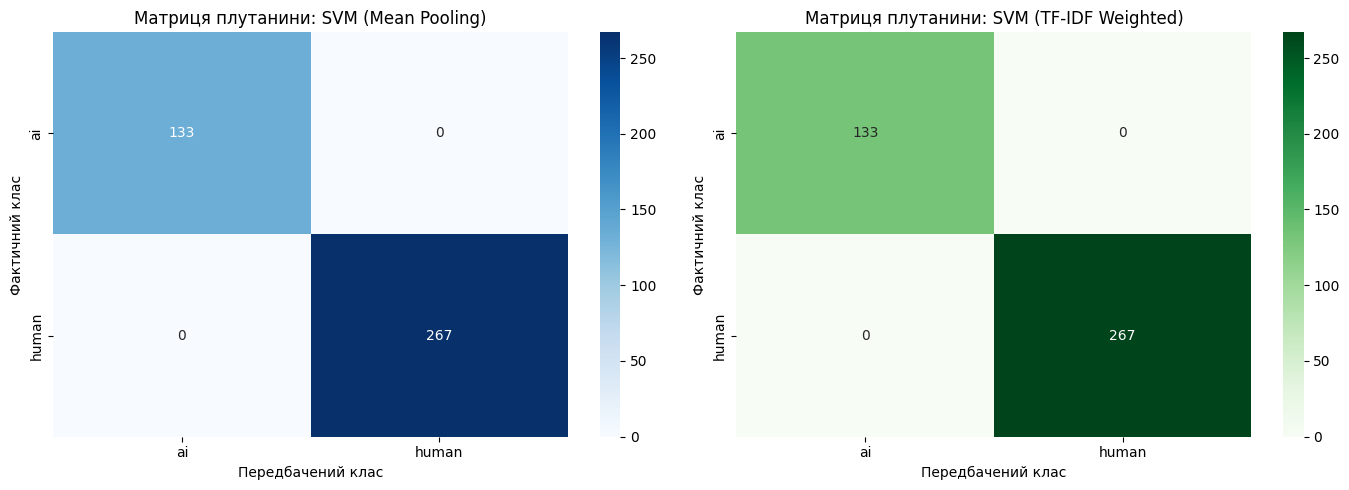

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix
import numpy as np

print("1. t-SNE Візуалізація векторних просторів")
print("Обчислення t-SNE (це може зайняти хвилину)...")

# Налаштування t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)

# Застосовуємо t-SNE до векторів Mean Pooling
X_mean_2d = tsne.fit_transform(X_mean)
# Застосовуємо t-SNE до векторів TF-IDF
X_tfidf_2d = tsne.fit_transform(X_tfidf)

# Створюємо графіки
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Палітра для класів (Human / AI)
palette = sns.color_palette("husl", 2)

# Графік 1: Mean Pooling
sns.scatterplot(
    x=X_mean_2d[:, 0], y=X_mean_2d[:, 1],
    hue=df[label_col], palette=palette, alpha=0.7, ax=axes[0]
)
axes[0].set_title("t-SNE: Mean Pooling")
axes[0].set_xlabel("Вимір 1")
axes[0].set_ylabel("Вимір 2")

# Графік 2: TF-IDF Weighted Mean
sns.scatterplot(
    x=X_tfidf_2d[:, 0], y=X_tfidf_2d[:, 1],
    hue=df[label_col], palette=palette, alpha=0.7, ax=axes[1]
)
axes[1].set_title("t-SNE: TF-IDF Weighted Mean")
axes[1].set_xlabel("Вимір 1")
axes[1].set_ylabel("Вимір 2")

plt.tight_layout()
plt.show()

print("\n2. Матриці плутанини (Confusion Matrices)")
# Ми покажемо матриці для одного найкращого класифікатора (SVM),
# оскільки результати дуже схожі.

from sklearn.model_selection import train_test_split
X_train_mean, X_test_mean, y_train, y_test = train_test_split(X_mean, y, test_size=0.2, random_state=42, stratify=y)
X_train_tfidf, X_test_tfidf, _, _ = train_test_split(X_tfidf, y, test_size=0.2, random_state=42, stratify=y)

# Навчаємо SVM для матриць
svm_mean = SVC(kernel='rbf', random_state=42).fit(X_train_mean, y_train)
svm_tfidf = SVC(kernel='rbf', random_state=42).fit(X_train_tfidf, y_train)

# Робимо передбачення
y_pred_mean = svm_mean.predict(X_test_mean)
y_pred_tfidf = svm_tfidf.predict(X_test_tfidf)

# Отримуємо назви класів зі LabelEncoder
class_names = le.classes_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Матриця для Mean Pooling
cm_mean = confusion_matrix(y_test, y_pred_mean)
sns.heatmap(cm_mean, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title('Матриця плутанини: SVM (Mean Pooling)')
axes[0].set_xlabel('Передбачений клас')
axes[0].set_ylabel('Фактичний клас')

# Матриця для TF-IDF
cm_tfidf = confusion_matrix(y_test, y_pred_tfidf)
sns.heatmap(cm_tfidf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title('Матриця плутанини: SVM (TF-IDF Weighted)')
axes[1].set_xlabel('Передбачений клас')
axes[1].set_ylabel('Фактичний клас')

plt.tight_layout()
plt.show()